# Business Formation Analysis Project

This notebook is a starting point for exploring business formation data in the USA. The goal is to create a RandomForest model that predicts current week state level business formation. Based on state data (excluding current week BA_NSA - see the feature name legend below) AND  national formation data including up to current week. Additionally some exploratory statistics of the data are made including graphs and the secondary aim is to identify if some of the features are more useful to predict the state level current week applications counts.

More precisely: the random forest model will classify current week state level BA_NSA as an increase, decrease or constant compared to the previous week. Without seeing the current week BA_NSA value.

## Questions

- Can current week state level business formation be predicted accurately? (INCREASE vs DECREASE vs CONSTANT)
- Which features have the highest explanatory power for current week state level application.
- Can Random Forest model achieve better prediction accuracy than a naive random classification?

## Data and analysis

The data source is Business Formation Statistics (BFS) from the U.S. Census Bureau at: www.census.gov

Two .csv datasets are used:
- bfs_us_apps_weekly_nsa.csv
- bfs_state_apps_weekly_nsa.csv

In [40]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import sklearn
from scipy import stats
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix
from sklearn.utils.validation import check_array
from IPython.display import display
from numpy.random import randint

#pd.set_option("display.max_columns", 30)
#pd.set_option("display.width", 140)

TIME_KEYS = ["Year", "Week"]

us_raw = pd.read_csv("bfs_us_apps_weekly_nsa.csv")
state_raw = pd.read_csv("bfs_state_apps_weekly_nsa.csv")

us_raw.head()

,Year,Week,BA_NSA,HBA_NSA,WBA_NSA,CBA_NSA,YY_BA_NSA,YY_HBA_NSA,YY_WBA_NSA,YY_CBA_NSA
0,2006,1,39250,23240,14950,12790,NaN,NaN,NaN,NaN
1,2006,2,36820,23820,15810,14410,NaN,NaN,NaN,NaN
2,2006,3,62920,38330,24430,21690,NaN,NaN,NaN,NaN
3,2006,4,51520,31460,20260,17260,NaN,NaN,NaN,NaN
4,2006,5,60890,36520,22800,19900,NaN,NaN,NaN,NaN


state_raw.head()

## Reshape state data and merge national features

In [41]:
# Validate and normalize the time keys before reshaping or joining.
required_state = set(TIME_KEYS + ["State"])
required_us = set(TIME_KEYS)
if not required_state.issubset(state_raw.columns):
    raise ValueError(f"State file is missing required columns: {sorted(required_state - set(state_raw.columns))}")
if not required_us.issubset(us_raw.columns):
    raise ValueError(f"U.S. file is missing required columns: {sorted(required_us - set(us_raw.columns))}")

state_data = state_raw.copy()
us_data = us_raw.copy()
for frame in (state_data, us_data):
    for key in TIME_KEYS:
        frame[key] = pd.to_numeric(frame[key], errors="raise").astype("int64")

state_data["State"] = state_data["State"].astype("string").str.strip()
if state_data["State"].isna().any() or state_data["State"].eq("").any():
    raise ValueError("State file contains a missing or blank State value.")

state_features = [column for column in state_data.columns if column not in TIME_KEYS + ["State"]]
us_features = [column for column in us_data.columns if column not in TIME_KEYS]
if not state_features or not us_features:
    raise ValueError("Expected at least one non-time feature in each source file.")

for column in state_features:
    state_data[column] = pd.to_numeric(state_data[column], errors="raise")
for column in us_features:
    us_data[column] = pd.to_numeric(us_data[column], errors="raise")

state_key = TIME_KEYS + ["State"]
if state_data.duplicated(state_key).any():
    examples = state_data.loc[state_data.duplicated(state_key, keep=False), state_key].head()
    raise ValueError(f"State data has duplicate state-week records. Examples:\n{examples}")
if us_data.duplicated(TIME_KEYS).any():
    examples = us_data.loc[us_data.duplicated(TIME_KEYS, keep=False), TIME_KEYS].head()
    raise ValueError(f"U.S. data has duplicate week records. Examples:\n{examples}")

def reshape_and_merge_sources(state_data, us_data, time_keys, state_features, us_features):
    """

    Args:
      state_data: 
      us_data: 
      time_keys: 
      state_features: 
      us_features: 

    Returns:

    """
    # Pivot produces (feature, State) column pairs; flip that order for State_feature names.
    state_wide = state_data.pivot(index=time_keys, columns="State", values=state_features)
    state_wide.columns = [f"{state}_{feature}" for feature, state in state_wide.columns]
    state_wide = state_wide.reset_index()

    us_prefixed = us_data.rename(columns={column: f"USA_{column}" for column in us_features})

    # Outer join preserves every observed week from either source; unmatched weeks remain visible as missing values.
    combined = state_wide.merge(
        us_prefixed,
        on=time_keys,
        how="outer",
        validate="one_to_one",
        indicator="_source_match",
    ).sort_values(time_keys).reset_index(drop=True)

    source_match_counts = combined["_source_match"].value_counts().reindex(
        ["both", "left_only", "right_only"], fill_value=0
    )
    combined = combined.drop(columns="_source_match")
    return combined, source_match_counts


combined, source_match_counts = reshape_and_merge_sources(
    state_data, us_data, TIME_KEYS, state_features, us_features
)

#print(f"State-wide data: {state_wide.shape[0]:,} weeks x {state_wide.shape[1]} columns")
#print(f"Merged data: {combined.shape[0]:,} weeks x {combined.shape[1]} columns")
#print("Week coverage (both / state only / U.S. only):", source_match_counts.to_dict())
#print("States:", state_data["State"].nunique())
#first_week = combined.iloc[0]
#last_week = combined.iloc[-1]
#print(f"Time-key range: {int(first_week['Year'])} week {int(first_week['Week'])} "
#      f"to {int(last_week['Year'])} week {int(last_week['Week'])}")
#display(combined.head())

## Weekly application trends

The plot showcases `BA_NSA` as an initial headline measure. Counts are not seasonally adjusted, so recurring within-year patterns should be kept in mind.

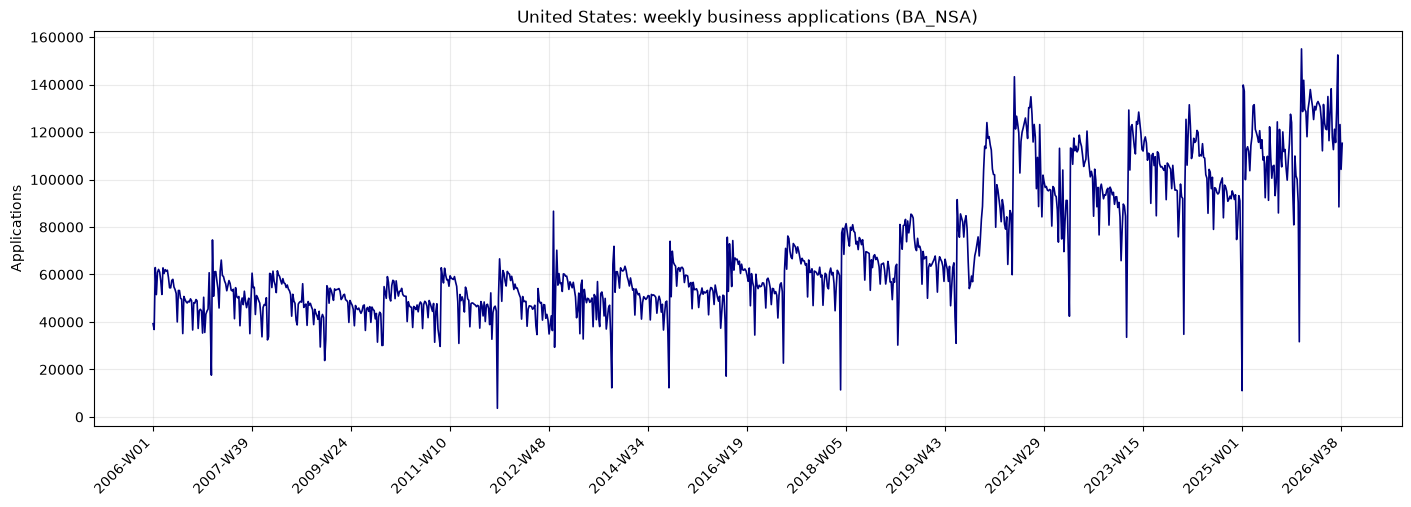

In [42]:
fig, axes = plt.subplots(2, 1, figsize=(14, 9), constrained_layout=True)

if "USA_BA_NSA" in combined.columns:
    national = combined.dropna(subset=["USA_BA_NSA"]).copy()
    national["Time"] = national["Year"].astype(str) + "-W" + national["Week"].astype(str).str.zfill(2)
    axes[0].plot(national["Time"], national["USA_BA_NSA"], color="navy", linewidth=1.2)
    axes[0].set_title("United States: weekly business applications (BA_NSA)")
    axes[0].set_ylabel("Applications")
    axes[0].grid(alpha=0.25)
    tick_step = max(1, len(national) // 12)
    axes[0].set_xticks(range(0, len(national), tick_step))
    axes[0].set_xticklabels(national["Time"].iloc[::tick_step], rotation=45, ha="right")

axes[1].set_visible(False)

plt.show()

## Combined data quality and distribution analysis
Check for Nans and conduct normality testing.

In [43]:
missing_counts = combined.isna().sum().sort_values(ascending=False)
missing_summary = missing_counts.rename("missing_count").to_frame()
missing_summary["missing_fraction"] = missing_summary["missing_count"] / len(combined)
print("Missing values by column (all columns):")
display(missing_summary)

time_values = combined[["Year", "Week"]].to_numpy(dtype=np.float64)
time_keys_present = np.isfinite(time_values).all()
if not time_keys_present:
    chronology_ok = False
    duplicate_time_key_count = np.nan
    out_of_order_pair_count = np.nan
else:
    years = time_values[:, 0]
    weeks = time_values[:, 1]
    duplicate_time_key_count = int(combined.duplicated(["Year", "Week"]).sum())
    out_of_order_pairs = (years[1:] < years[:-1]) | (
        (years[1:] == years[:-1]) & (weeks[1:] < weeks[:-1])
    )
    out_of_order_pair_count = int(np.count_nonzero(out_of_order_pairs))
    chronology_ok = duplicate_time_key_count == 0 and out_of_order_pair_count == 0

Missing values by column (all columns):


,missing_count,missing_fraction
USA_YY_CBA_NSA,55,0.050832
SD_YY_CBA_NSA,55,0.050832
SC_YY_CBA_NSA,55,0.050832
RI_YY_CBA_NSA,55,0.050832
PA_YY_CBA_NSA,55,0.050832
...,...,...
NC_BA_NSA,0,0.000000
ND_BA_NSA,0,0.000000
NE_BA_NSA,0,0.000000
NH_BA_NSA,0,0.000000


In [44]:
feature_columns = [
    column
    for column in combined.select_dtypes(include=[np.number]).columns
    if column not in ["Year", "Week"]
]
if not feature_columns:
    raise ValueError("No numeric feature columns were found in combined.")

feature_matrix = combined[feature_columns].to_numpy(dtype=np.float64)
statistics_rows = []
for column_index, column in enumerate(feature_columns):
    values = feature_matrix[:, column_index]
    valid_values = values[np.isfinite(values)]
    if valid_values.size:
        # Validate finite observations with scikit-learn before numerical calculations.
        valid_values = check_array(valid_values.reshape(-1, 1), dtype=np.float64).ravel()
        mean = float(np.mean(valid_values))
        st_dev = float(np.std(valid_values, ddof=1)) if valid_values.size > 1 else np.nan
    else:
        mean = np.nan
        st_dev = np.nan

    if valid_values.size >= 3 and st_dev > 0:
        jb_result = stats.jarque_bera(valid_values)
        jb_statistic = float(jb_result.statistic)
        jb_p_value = float(jb_result.pvalue)
        normality_result = "Reject normality" if jb_p_value < 0.05 else "Fail to reject normality"
    else:
        jb_statistic = np.nan
        jb_p_value = np.nan
        normality_result = "Not testable (fewer than 3 finite values or zero variance)"

    statistics_rows.append(
        {
            "feature": column,
            "n_finite": int(valid_values.size),
            "mean": mean,
            "st_dev": st_dev,
            "jarque_bera_statistic": jb_statistic,
            "jarque_bera_p_value": jb_p_value,
            "normality_at_0.05": normality_result,
        }
    )

feature_statistics = pd.DataFrame(statistics_rows).set_index("feature")
feature_statistics

,n_finite,mean,st_dev,jarque_bera_statistic,jarque_bera_p_value,normality_at_0.05
feature,,,,,,
AK_BA_NSA,1082,140.203327,55.941651,1.710417e+03,0.000000e+00,Reject normality
AL_BA_NSA,1082,869.048059,404.424786,2.251181e+02,1.306833e-49,Reject normality
AR_BA_NSA,1082,506.617375,211.865464,1.877468e+02,1.703316e-41,Reject normality
AZ_BA_NSA,1082,1568.659889,642.035498,2.002714e+02,3.248038e-44,Reject normality
CA_BA_NSA,1082,7124.001848,2623.376653,1.341989e+02,7.229034e-30,Reject normality
...,...,...,...,...,...,...
USA_CBA_NSA,1082,11293.012939,2549.362507,7.878224e+02,8.443716e-172,Reject normality
USA_YY_BA_NSA,1027,8.125852,46.786791,3.010855e+06,0.000000e+00,Reject normality
USA_YY_HBA_NSA,1027,3.935083,43.147826,2.937275e+06,0.000000e+00,Reject normality


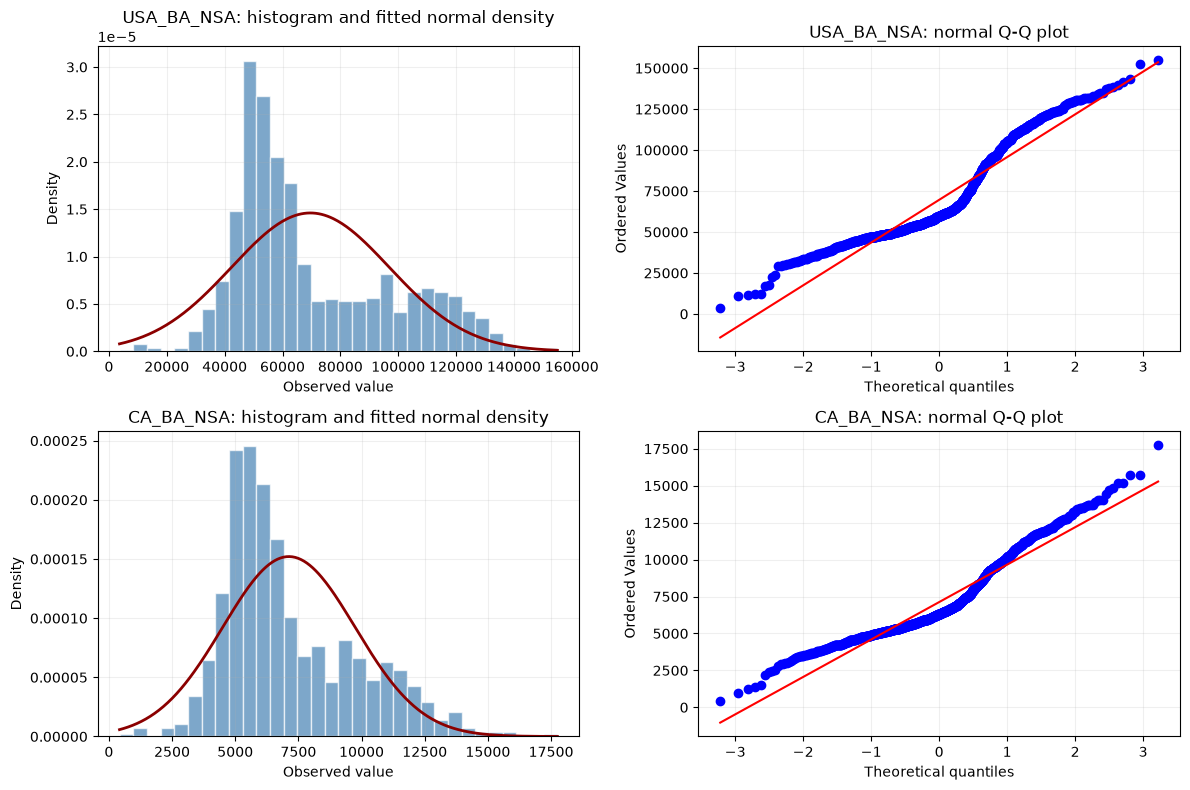

In [45]:
plot_features = [
    column for column in ("USA_BA_NSA", "CA_BA_NSA")
    if column in feature_columns and np.isfinite(feature_matrix[:, feature_columns.index(column)]).sum() >= 3
]
if not plot_features:
    plot_features = [
        column for column in feature_columns
        if np.isfinite(feature_matrix[:, feature_columns.index(column)]).sum() >= 3
    ][:2]

if not plot_features:
    print("No feature has enough finite values to create normality plots.")
else:
    figure, axes = plt.subplots(len(plot_features), 2, figsize=(12, 4 * len(plot_features)), squeeze=False)
    for row, column in enumerate(plot_features):
        values = feature_matrix[:, feature_columns.index(column)]
        values = values[np.isfinite(values)]
        mean = np.mean(values)
        st_dev = np.std(values, ddof=1)

        axes[row, 0].hist(
            values,
            bins=min(40, max(10, int(np.sqrt(values.size)))),
            density=True,
            alpha=0.7,
            color="steelblue",
            edgecolor="white",
        )
        if st_dev > 0:
            x_grid = np.linspace(np.min(values), np.max(values), 300)
            axes[row, 0].plot(x_grid, stats.norm.pdf(x_grid, loc=mean, scale=st_dev), color="darkred", linewidth=2)
        axes[row, 0].set_title(f"{column}: histogram and fitted normal density")
        axes[row, 0].set_xlabel("Observed value")
        axes[row, 0].set_ylabel("Density")
        axes[row, 0].grid(alpha=0.2)

        stats.probplot(values, dist="norm", plot=axes[row, 1])
        axes[row, 1].set_title(f"{column}: normal Q-Q plot")
        axes[row, 1].grid(alpha=0.2)

    figure.tight_layout()
    plt.show()

## Random forest classification data preparation

The target is the direction of change in each state's weekly `BA_NSA` applications versus its preceding observation: `DECREASED`, `CONSTANT`, or `INCREASED`. For each target week, predictors include the preceding 52 state-week observations for that state's available features, contemporaneous `USA_` features, and a one-hot state identifier. The target week's state values are never predictors. Samples are split chronologically by target year: 2006–2023 for training and 2024–2026 for testing. Missing predictor values are imputed using training-set medians only.

In [46]:
LAG_WEEKS = 52
CLASS_NAMES = np.array(["DECREASED", "CONSTANT", "INCREASED"])
CLASS_TO_CODE = {name: code for code, name in enumerate(CLASS_NAMES)}

if combined.duplicated(["Year", "Week"]).any():
    raise ValueError("combined must have one row per Year/Week before creating model samples.")
time_values = combined[["Year", "Week"]].to_numpy(dtype=np.int64)
if np.any((time_values[1:, 0] < time_values[:-1, 0]) | (
    (time_values[1:, 0] == time_values[:-1, 0]) & (time_values[1:, 1] < time_values[:-1, 1])
)):
    raise ValueError("combined must be in chronological Year/Week order before creating lag features.")

state_names = sorted(state_data["State"].dropna().unique().tolist())
state_feature_names = list(state_features)
national_feature_names = [column for column in combined.columns if column.startswith("USA_")]
missing_model_columns = [
    f"{state}_{feature}"
    for state in state_names
    for feature in state_feature_names
    if f"{state}_{feature}" not in combined.columns
] + [column for column in national_feature_names if column not in combined.columns]
if missing_model_columns or "BA_NSA" not in state_feature_names:
    raise ValueError(f"Required model features are unavailable: {missing_model_columns[:10]}")
if not national_feature_names:
    raise ValueError("No USA-prefixed national features are available.")
if len(combined) <= LAG_WEEKS:
    raise ValueError(f"At least {LAG_WEEKS + 1} weekly observations are required.")

state_input_columns = [f"{state}_{feature}" for feature in state_feature_names for state in state_names]
state_input_matrix = combined[state_input_columns].to_numpy(dtype=np.float64).reshape(
    len(combined), len(state_feature_names), len(state_names)
)
national_input_matrix = combined[national_feature_names].to_numpy(dtype=np.float64)
lag_feature_names = [
    f"lag_{lag:02d}_{feature}"
    for lag in range(LAG_WEEKS, 0, -1)
    for feature in state_feature_names
]
model_feature_names = lag_feature_names + national_feature_names + [f"state_{state}" for state in state_names]

def build_lagged_samples(
    state_input_matrix,
    national_input_matrix,
    state_names,
    state_feature_names,
    time_values,
    lag_weeks,
):
    """

    Args:
      state_input_matrix: 
      national_input_matrix: 
      state_names: 
      state_feature_names: 
      time_values: 
      lag_weeks: 

    Returns:

    """
    sample_features = []
    sample_labels = []
    sample_years = []
    sample_weeks = []
    sample_states = []
    application_feature_index = state_feature_names.index("BA_NSA")
    state_codes = {state: index for index, state in enumerate(state_names)}

    for state in state_names:
        state_index = state_codes[state]
        state_applications = state_input_matrix[:, application_feature_index, state_index]
        state_indicator = np.zeros(len(state_names), dtype=np.float64)
        state_indicator[state_index] = 1.0

        for target_index in range(lag_weeks, len(time_values)):
            previous_applications = state_applications[target_index - 1]
            current_applications = state_applications[target_index]
            if not np.isfinite(previous_applications) or not np.isfinite(current_applications):
                continue

            change = np.sign(current_applications - previous_applications)
            class_code = int(change + 1)
            historical_features = state_input_matrix[target_index - lag_weeks:target_index, :, state_index].reshape(-1)
            current_national_features = national_input_matrix[target_index]
            sample_features.append(np.concatenate((historical_features, current_national_features, state_indicator)))
            sample_labels.append(class_code)
            sample_years.append(int(time_values[target_index, 0]))
            sample_weeks.append(int(time_values[target_index, 1]))
            sample_states.append(state)

    X = np.asarray(sample_features, dtype=np.float64)
    y = np.asarray(sample_labels, dtype=np.int8)
    sample_years = np.asarray(sample_years, dtype=np.int64)
    sample_weeks = np.asarray(sample_weeks, dtype=np.int64)
    sample_states = np.asarray(sample_states, dtype=str)
    return X, y, sample_years, sample_weeks, sample_states


X, y, sample_years, sample_weeks, sample_states = build_lagged_samples(
    state_input_matrix,
    national_input_matrix,
    state_names,
    state_feature_names,
    time_values,
    LAG_WEEKS,
)

train_mask = sample_years <= 2023
test_mask = (sample_years >= 2024) & (sample_years <= 2026)
if not train_mask.any() or not test_mask.any():
    raise ValueError("The dataset must contain usable training observations through 2023 and test observations in 2024–2026.")
if np.any(~np.isfinite(sample_years)):
    raise ValueError("Model sample years must be finite.")

X_train_raw = X[train_mask]
X_test_raw = X[test_mask]
y_train = y[train_mask]
y_test = y[test_mask]
train_feature_medians = np.nanmedian(
    np.where(np.isfinite(X_train_raw), X_train_raw, np.nan), axis=0
)
train_feature_medians = np.where(np.isfinite(train_feature_medians), train_feature_medians, 0.0)
X_train = np.where(np.isfinite(X_train_raw), X_train_raw, train_feature_medians)
X_test = np.where(np.isfinite(X_test_raw), X_test_raw, train_feature_medians)
X_train = check_array(X_train, dtype=np.float64)
X_test = check_array(X_test, dtype=np.float64)

print(f"Samples: {len(y):,}; features: {len(model_feature_names):,}")
print(f"Training samples (through 2023): {len(y_train):,}")
print(f"Testing samples (2024–2026): {len(y_test):,}")
print("Training class counts:", dict(zip(CLASS_NAMES, np.bincount(y_train, minlength=len(CLASS_NAMES)))))
print("Testing class counts:", dict(zip(CLASS_NAMES, np.bincount(y_test, minlength=len(CLASS_NAMES)))))

Samples: 52,530; features: 475
Training samples (through 2023): 45,186
Testing samples (2024–2026): 7,344
Training class counts: {np.str_('DECREASED'): np.int64(22384), np.str_('CONSTANT'): np.int64(3022), np.str_('INCREASED'): np.int64(19780)}
Testing class counts: {np.str_('DECREASED'): np.int64(3638), np.str_('CONSTANT'): np.int64(290), np.str_('INCREASED'): np.int64(3416)}


## Training the random forest

Adjust `MAX_TREE_DEPTH` to tune the maximum depth. The random forest is fitted only on the training period (through 2023); the same `model` object is retained for test-set prediction.

In [47]:
MAX_TREE_DEPTH = 7

model = RandomForestClassifier(
    n_estimators=100,
    max_depth=MAX_TREE_DEPTH,
    random_state=42,
    n_jobs=-1,
)
model.fit(X_train, y_train)

print(f"Fitted {model.__class__.__name__} on {len(y_train):,} samples.")
print(f"Maximum tree depth: {MAX_TREE_DEPTH}")

Fitted RandomForestClassifier on 45,186 samples.
Maximum tree depth: 7


### Training-set in-sample evaluation

These predictions are made on the same training observations used to fit the model, so they are an in-sample diagnostic and can be optimistic. The confusion matrix uses actual classes as rows and predicted classes as columns. TP/FP/TN/FN are also reported one-vs-rest for each direction class.

In [48]:
train_predictions = model.predict(X_train)
train_confusion_matrix = confusion_matrix(y_train, train_predictions, labels=np.arange(len(CLASS_NAMES)))
train_accuracy = np.trace(train_confusion_matrix) / train_confusion_matrix.sum()
train_class_results = []
for class_index, class_name in enumerate(CLASS_NAMES):
    true_positive = int(train_confusion_matrix[class_index, class_index])
    false_positive = int(train_confusion_matrix[:, class_index].sum() - true_positive)
    false_negative = int(train_confusion_matrix[class_index, :].sum() - true_positive)
    true_negative = int(train_confusion_matrix.sum() - true_positive - false_positive - false_negative)
    class_recall = true_positive / (true_positive + false_negative) if true_positive + false_negative else np.nan
    train_class_results.append(
        {"class": class_name, "TP": true_positive, "FP": false_positive, "TN": true_negative, "FN": false_negative, "recall": class_recall}
    )

print(f"Training in-sample accuracy: {train_accuracy:.4f}")
print(f"Training macro recall: {np.nanmean([row['recall'] for row in train_class_results]):.4f}")
display(pd.DataFrame(train_confusion_matrix, index=CLASS_NAMES, columns=CLASS_NAMES).rename_axis("Actual \\ Predicted"))
display(pd.DataFrame(train_class_results).set_index("class"))

Training in-sample accuracy: 0.7044
Training macro recall: 0.4994


,DECREASED,CONSTANT,INCREASED
Actual \ Predicted,,,
DECREASED,18861,0,3523
CONSTANT,1591,0,1431
INCREASED,6813,0,12967


,TP,FP,TN,FN,recall
class,,,,,
DECREASED,18861,8404,14398,3523,0.842611
CONSTANT,0,0,42164,3022,0.000000
INCREASED,12967,4954,20452,6813,0.655561


## Testing on 2024–2026

Predict the held-out 2024–2026 observations with the model fitted on data through 2023. No refitting occurs in this section. Accuracy is overall multiclass accuracy; recall is reported per class and as macro recall across the three direction classes.

In [58]:
test_predictions = model.predict(X_test)
test_confusion_matrix = confusion_matrix(y_test, test_predictions, labels=np.arange(len(CLASS_NAMES)))
test_accuracy = np.trace(test_confusion_matrix) / test_confusion_matrix.sum()
test_class_results = []
for class_index, class_name in enumerate(CLASS_NAMES):
    true_positive = int(test_confusion_matrix[class_index, class_index])
    false_positive = int(test_confusion_matrix[:, class_index].sum() - true_positive)
    false_negative = int(test_confusion_matrix[class_index, :].sum() - true_positive)
    true_negative = int(test_confusion_matrix.sum() - true_positive - false_positive - false_negative)
    class_recall = true_positive / (true_positive + false_negative) if true_positive + false_negative else np.nan
    test_class_results.append(
        {"class": class_name, "TP": true_positive, "FP": false_positive, "TN": true_negative, "FN": false_negative, "recall": class_recall}
    )

print(f"Test-set accuracy: {test_accuracy:.4f}")
print(f"Test macro recall: {np.nanmean([row['recall'] for row in test_class_results]):.4f}")
display(pd.DataFrame(test_confusion_matrix, index=CLASS_NAMES, columns=CLASS_NAMES).rename_axis("Actual \\ Predicted"))
display(pd.DataFrame(test_class_results).set_index("class"))
list(test_predictions)

Test-set accuracy: 0.6228
Test macro recall: 0.4290


,DECREASED,CONSTANT,INCREASED
Actual \ Predicted,,,
DECREASED,2918,0,720
CONSTANT,179,0,111
INCREASED,1760,0,1656


,TP,FP,TN,FN,recall
class,,,,,
DECREASED,2918,1939,1767,720,0.802089
CONSTANT,0,0,7054,290,0.000000
INCREASED,1656,831,3097,1760,0.484778


[np.int8(2),
 np.int8(0),
 np.int8(2),
 np.int8(2),
 np.int8(2),
 np.int8(2),
 np.int8(2),
 np.int8(2),
 np.int8(2),
 np.int8(2),
 np.int8(0),
 np.int8(0),
 np.int8(2),
 np.int8(0),
 np.int8(0),
 np.int8(0),
 np.int8(0),
 np.int8(0),
 np.int8(0),
 np.int8(0),
 np.int8(2),
 np.int8(0),
 np.int8(2),
 np.int8(2),
 np.int8(0),
 np.int8(2),
 np.int8(0),
 np.int8(2),
 np.int8(0),
 np.int8(2),
 np.int8(0),
 np.int8(0),
 np.int8(0),
 np.int8(0),
 np.int8(2),
 np.int8(2),
 np.int8(2),
 np.int8(2),
 np.int8(0),
 np.int8(0),
 np.int8(2),
 np.int8(0),
 np.int8(0),
 np.int8(0),
 np.int8(0),
 np.int8(0),
 np.int8(2),
 np.int8(0),
 np.int8(0),
 np.int8(2),
 np.int8(2),
 np.int8(0),
 np.int8(0),
 np.int8(2),
 np.int8(0),
 np.int8(0),
 np.int8(0),
 np.int8(0),
 np.int8(2),
 np.int8(0),
 np.int8(0),
 np.int8(0),
 np.int8(0),
 np.int8(0),
 np.int8(2),
 np.int8(0),
 np.int8(0),
 np.int8(0),
 np.int8(2),
 np.int8(0),
 np.int8(2),
 np.int8(0),
 np.int8(0),
 np.int8(0),
 np.int8(0),
 np.int8(2),
 np.int8(0),

***Question 1:*** 
Can current week state level business formation be predicted accurately? (INCREASE vs DECREASE vs CONSTANT)
***Answer:***
Yes the model using tree depth of 7 was able to achieve a test-set accuracy of 0.623

## Naive classification benchmark

In [ ]:
test_predictions = [randint(0, 1)*2 for _ in list(test_predictions)]  # Random predictions for testing purposes
test_confusion_matrix = confusion_matrix(y_test, test_predictions, labels=np.arange(len(CLASS_NAMES)))
test_accuracy = np.trace(test_confusion_matrix) / test_confusion_matrix.sum()
test_class_results = []
for class_index, class_name in enumerate(CLASS_NAMES):
    true_positive = int(test_confusion_matrix[class_index, class_index])
    false_positive = int(test_confusion_matrix[:, class_index].sum() - true_positive)
    false_negative = int(test_confusion_matrix[class_index, :].sum() - true_positive)
    true_negative = int(test_confusion_matrix.sum() - true_positive - false_positive - false_negative)
    class_recall = true_positive / (true_positive + false_negative) if true_positive + false_negative else np.nan
    test_class_results.append(
        {"class": class_name, "TP": true_positive, "FP": false_positive, "TN": true_negative, "FN": false_negative, "recall": class_recall}
    )

print(f"Test-set accuracy: {test_accuracy:.4f}")
print(f"Test macro recall: {np.nanmean([row['recall'] for row in test_class_results]):.4f}")
display(pd.DataFrame(test_confusion_matrix, index=CLASS_NAMES, columns=CLASS_NAMES).rename_axis("Actual \\ Predicted"))
display(pd.DataFrame(test_class_result***Question 1:*** 
Can current week state level business formation be predicted accurately? (INCREASE vs DECREASE vs CONSTANT)
***Answer:***
Yes the model using tree depth of 7 was able to achieve a test-set accuracy of 0.623s).set_index("class"))

Test-set accuracy: 0.4954
Test macro recall: 0.3333


,DECREASED,CONSTANT,INCREASED
Actual \ Predicted,,,
DECREASED,3638,0,0
CONSTANT,290,0,0
INCREASED,3416,0,0


,TP,FP,TN,FN,recall
class,,,,,
DECREASED,3638,3706,0,0,1.0
CONSTANT,0,0,7054,290,0.0
INCREASED,0,0,3928,3416,0.0


***Question 3:*** 
Can Random Forest model achieve better prediction accuracy than a naive random classification?
***Answer:***
Yes the model has a test-set accuracy of 0.623 vs 0.4954 for the naive random classificator.

## Feature strength

Random-forest MDI importances provides a first view of which lagged state features, current-week national features, and state identifiers are best for tree splits.

,importance
feature,
USA_CBA_NSA,0.091150
USA_HBA_NSA,0.075660
lag_01_YY_BA_NSA,0.074413
lag_01_YY_HBA_NSA,0.058449
USA_WBA_NSA,0.057380
USA_BA_NSA,0.055216
USA_YY_BA_NSA,0.045414
USA_YY_HBA_NSA,0.035493
lag_01_YY_WBA_NSA,0.034322


Total importance by feature group:


,importance
feature_group,
Lagged state features,0.586017
Current-week national features,0.413743
State identity,0.000240


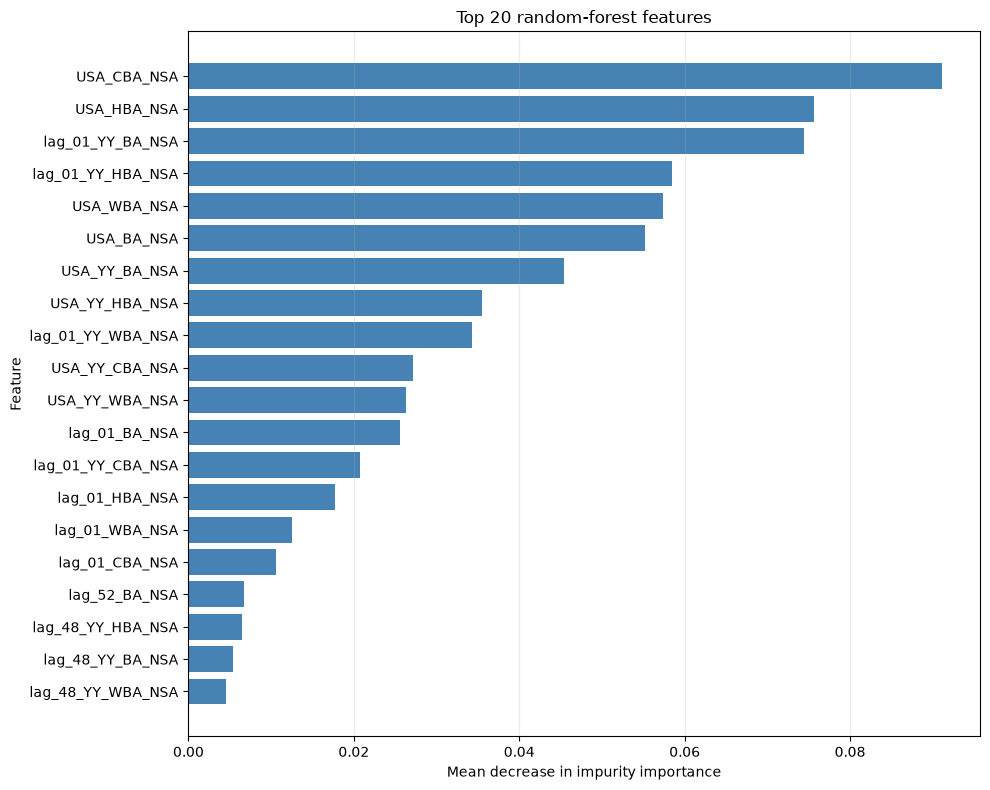

In [62]:
feature_importance = pd.DataFrame(
    {"feature": model_feature_names, "importance": model.feature_importances_}
).sort_values("importance", ascending=False, ignore_index=True)
display(feature_importance.head(30).set_index("feature"))

feature_importance["feature_group"] = np.select(
    [
        feature_importance["feature"].str.startswith("USA_"),
        feature_importance["feature"].str.startswith("state_"),
    ],
    ["Current-week national features", "State identity"],
    default="Lagged state features",
)
group_importance = feature_importance.groupby("feature_group", as_index=True)["importance"].sum().sort_values(ascending=False)
print("Total importance by feature group:")
display(group_importance.to_frame())

top_features = feature_importance.head(20).sort_values("importance")
plt.figure(figsize=(10, 8))
plt.barh(top_features["feature"], top_features["importance"], color="steelblue")
plt.title("Top 20 random-forest features")
plt.xlabel("Mean decrease in impurity importance")
plt.ylabel("Feature")
plt.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

***Question 2:*** 
Which features have the highest explanatory power for current week state level application?
***Answer:***
- National current CBA_NSA
- National current HBA_NSA
- Previous week state CBA_NSA